# Stage 3 — Baseline Classifier (TF-IDF + Logistic Regression)

DCIT 316 — Detecting Clickbait and Sensationalism in Ghanaian Online News Headlines.

Trains the interpretable baseline on `data/processed/annotated_headlines.csv` (1,000 headlines, Ambiguous excluded from training per the project proposal), evaluates it on a standard 80/20 split, inspects the top predictive n-grams, and runs a held-out-outlet generalization check (train on 6 outlets, test on the 7th it has never seen) to check the model is learning clickbait language rather than outlet-specific formatting quirks.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_recall_fscore_support,
)

sys.path.insert(0, os.path.abspath(".."))
from models.data import load_labeled_dataset, make_train_test_split, held_out_outlet_split

sns.set_theme(style="whitegrid")
RANDOM_SEED = 42

## Load the dataset

In [2]:
df = load_labeled_dataset("../data/processed/annotated_headlines.csv")
print(f"Total labeled headlines (Ambiguous excluded from training): {len(df)}")
df["label"].value_counts()

Total labeled headlines (Ambiguous excluded from training): 990


label
Informative    794
Clickbait      196
Name: count, dtype: int64

## Standard 80/20 evaluation

Stratified random split, fixed seed — this is the same split Stages 4 and 5 will use for the fine-tuned transformer and zero-shot comparisons.

In [3]:
train_df, test_df = make_train_test_split(df, test_size=0.2, seed=RANDOM_SEED)
print(f"Train: {len(train_df)}, Test: {len(test_df)}")
train_df["label"].value_counts(normalize=True).round(3)

Train: 792, Test: 198


label
Informative    0.802
Clickbait      0.198
Name: proportion, dtype: float64

In [4]:
pipeline = Pipeline(
    [
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)),
    ]
)
pipeline.fit(train_df["headline_text"], train_df["label"])
print(f"Vocabulary size: {len(pipeline.named_steps['tfidf'].vocabulary_)}")

Vocabulary size: 1902


              precision    recall  f1-score   support

   Clickbait      1.000     0.103     0.186        39
 Informative      0.820     1.000     0.901       159

    accuracy                          0.823       198
   macro avg      0.910     0.551     0.543       198
weighted avg      0.855     0.823     0.760       198



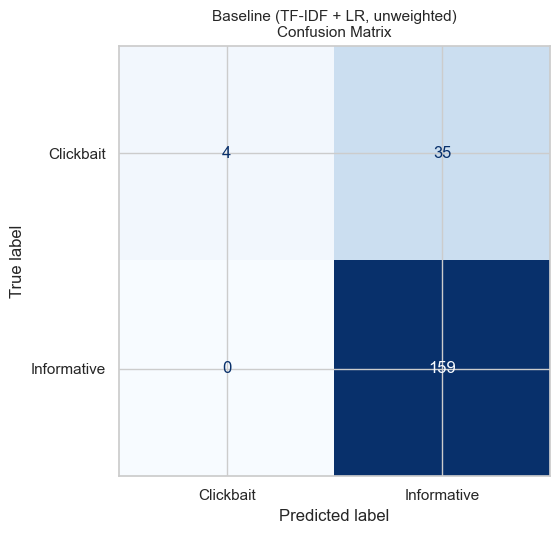

In [5]:
y_true = test_df["label"]
y_pred = pipeline.predict(test_df["headline_text"])

print(classification_report(y_true, y_pred, digits=3))

cm = confusion_matrix(y_true, y_pred, labels=pipeline.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipeline.classes_)
fig, ax = plt.subplots(figsize=(6, 5.5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Baseline (TF-IDF + LR, unweighted)\nConfusion Matrix", fontsize=11)
plt.tight_layout()
plt.show()

## Addressing class imbalance

The unweighted model above has Clickbait precision 1.000 but recall only
0.103 — with the dataset skewing ~80/20 Informative/Clickbait, unweighted
logistic regression can get 82% accuracy by defaulting to "always predict
Informative" and barely bothers with the minority class. That's not a useful
clickbait detector. Refitting with `class_weight="balanced"` (inversely
weights each class by its frequency) is standard practice for this and is
used as the actual baseline for the rest of this notebook.

              precision    recall  f1-score   support

   Clickbait      0.390     0.590     0.469        39
 Informative      0.885     0.774     0.826       159

    accuracy                          0.737       198
   macro avg      0.637     0.682     0.647       198
weighted avg      0.787     0.737     0.755       198



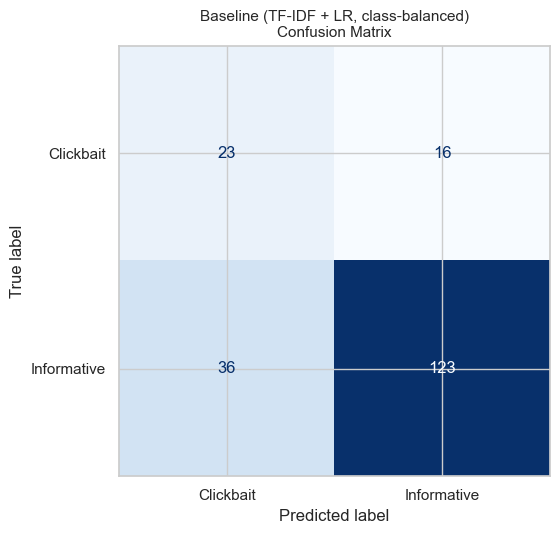

In [6]:
pipeline = Pipeline(
    [
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, class_weight="balanced")),
    ]
)
pipeline.fit(train_df["headline_text"], train_df["label"])

y_pred = pipeline.predict(test_df["headline_text"])
print(classification_report(y_true, y_pred, digits=3))

cm = confusion_matrix(y_true, y_pred, labels=pipeline.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipeline.classes_)
fig, ax = plt.subplots(figsize=(6, 5.5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Baseline (TF-IDF + LR, class-balanced)\nConfusion Matrix", fontsize=11)
plt.tight_layout()
plt.savefig("baseline_confusion_matrix.png", dpi=150)
plt.show()

## Top predictive features

The baseline's main advantage over the transformer/zero-shot models: full transparency into which words and phrases drive its decisions. Coefficients are signed so that positive = pushes toward Clickbait, regardless of `LogisticRegression`'s internal alphabetical class ordering.

In [7]:
feature_names = pipeline.named_steps["tfidf"].get_feature_names_out()
coefs = pipeline.named_steps["clf"].coef_[0]
classes = list(pipeline.named_steps["clf"].classes_)

# For binary LogisticRegression, a positive coefficient pushes toward classes_[1].
sign_for_clickbait = 1 if classes.index("Clickbait") == 1 else -1
clickbait_weight = coefs * sign_for_clickbait

TOP_N = 20
top_clickbait_idx = np.argsort(clickbait_weight)[-TOP_N:][::-1]
top_informative_idx = np.argsort(clickbait_weight)[:TOP_N]

top_clickbait = pd.DataFrame(
    {"feature": feature_names[top_clickbait_idx], "weight": clickbait_weight[top_clickbait_idx].round(3)}
)
top_informative = pd.DataFrame(
    {"feature": feature_names[top_informative_idx], "weight": (-clickbait_weight[top_informative_idx]).round(3)}
)

print(f"Top {TOP_N} n-grams most predictive of Clickbait:")
display(top_clickbait)
print(f"\nTop {TOP_N} n-grams most predictive of Informative:")
display(top_informative)

Top 20 n-grams most predictive of Clickbait:


,feature,weight
0,the,2.548
1,video,2.214
2,his,1.783
3,man,1.436
4,her,1.430
5,why,1.426
6,photos,1.354
7,boyfriend,1.325
8,abena,1.315
9,lady,1.310



Top 20 n-grams most predictive of Informative:


,feature,weight
0,ghana,1.188
1,to,1.029
2,mahama,1.004
3,over,0.814
4,president mahama,0.807
5,dies,0.786
6,2026,0.781
7,not,0.774
8,president,0.693
9,npp,0.680


## Held-out-outlet generalization check

Random 80/20 splits let a model succeed by memorizing outlet-specific formatting (byline patterns, boilerplate phrasing) rather than genuine clickbait language, since headlines from the same outlet appear in both train and test. This retrains the pipeline 7 times, each time holding out one entire outlet as the test set — a harder, more honest test of whether the model generalizes.

In [8]:
results = []
for outlet in sorted(df["outlet"].unique()):
    train_ho, test_ho = held_out_outlet_split(df, outlet)
    if train_ho["label"].nunique() < 2:
        print(f"Skipping {outlet}: training set missing a class")
        continue

    pipe_ho = Pipeline(
        [
            ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
            ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, class_weight="balanced")),
        ]
    )
    pipe_ho.fit(train_ho["headline_text"], train_ho["label"])
    y_pred_ho = pipe_ho.predict(test_ho["headline_text"])

    accuracy = accuracy_score(test_ho["label"], y_pred_ho)
    precision, recall, f1, _ = precision_recall_fscore_support(
        test_ho["label"], y_pred_ho, average="macro", zero_division=0
    )
    clickbait_precision, clickbait_recall, clickbait_f1, _ = precision_recall_fscore_support(
        test_ho["label"], y_pred_ho, labels=["Clickbait"], average="macro", zero_division=0
    )
    results.append(
        {
            "held_out_outlet": outlet,
            "source_style": test_ho["source_style"].iloc[0],
            "n_test": len(test_ho),
            "accuracy": round(accuracy, 3),
            "macro_f1": round(f1, 3),
            "clickbait_recall": round(clickbait_recall, 3),
        }
    )

held_out_results = pd.DataFrame(results)
held_out_results

,held_out_outlet,source_style,n_test,accuracy,macro_f1,clickbait_recall
0,citinewsroom,credible,154,0.968,0.714,0.333
1,ghpage,clickbait_heavy,164,0.634,0.613,0.440
2,gna,credible,155,0.987,0.747,0.500
3,graphic,credible,35,0.971,0.826,0.500
4,myjoyonline,credible,151,0.901,0.579,0.400
5,yen,clickbait_heavy,166,0.596,0.493,0.308
6,zionfelix,clickbait_heavy,165,0.594,0.590,0.612


In [9]:
random_split_accuracy = accuracy_score(y_true, y_pred)
random_split_clickbait_recall = precision_recall_fscore_support(
    y_true, y_pred, labels=["Clickbait"], average="macro", zero_division=0
)[1]
random_split_macro_f1 = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)[2]

print("Random 80/20 split:")
print(f"  accuracy={random_split_accuracy:.3f}  macro_f1={random_split_macro_f1:.3f}  clickbait_recall={random_split_clickbait_recall:.3f}")
print()

by_style = held_out_results.groupby("source_style")[["accuracy", "macro_f1", "clickbait_recall"]].mean().round(3)
print("Held-out-outlet, averaged by source style:")
print(by_style)
print()
print(
    "The raw accuracy comparison (mean held-out {:.3f} vs random-split {:.3f}) looks like generalization "
    "is fine, but that's an artifact of averaging: credible outlets score >0.94 held-out because the model "
    "can just default to Informative and be right almost every time. The clickbait-heavy outlets are the real "
    "test, and clickbait_recall collapses there ({:.3f} average, vs {:.3f} on the random split) -- the model "
    "leans heavily on outlet-specific vocabulary rather than portable clickbait style.".format(
        held_out_results["accuracy"].mean(),
        random_split_accuracy,
        held_out_results[held_out_results["source_style"] == "clickbait_heavy"]["clickbait_recall"].mean(),
        random_split_clickbait_recall,
    )
)

Random 80/20 split:
  accuracy=0.737  macro_f1=0.647  clickbait_recall=0.590

Held-out-outlet, averaged by source style:
                 accuracy  macro_f1  clickbait_recall
source_style                                         
clickbait_heavy     0.608     0.565             0.453
credible            0.957     0.716             0.433

The raw accuracy comparison (mean held-out 0.807 vs random-split 0.737) looks like generalization is fine, but that's an artifact of averaging: credible outlets score >0.94 held-out because the model can just default to Informative and be right almost every time. The clickbait-heavy outlets are the real test, and clickbait_recall collapses there (0.453 average, vs 0.590 on the random split) -- the model leans heavily on outlet-specific vocabulary rather than portable clickbait style.


## Summary

**Class imbalance mattered a lot.** Unweighted logistic regression got a
misleadingly good-looking 0.823 accuracy by defaulting to "Informative"
almost always (Clickbait recall 0.103). Class-balanced weighting drops
accuracy to 0.737 but is the actually-useful model: Clickbait recall 0.590,
precision 0.390, F1 0.469, macro F1 0.647. Accuracy alone is not a
trustworthy metric on this dataset — the paper should lead with
per-class/macro metrics, not accuracy.

**The held-out-outlet check found real evidence of outlet memorization, not
just topic memorization.** Averaged by source style: credible outlets hold
up fine (macro F1 0.716, though clickbait_recall there is noisy since
credible outlets have very few Clickbait examples to begin with). Clickbait-
heavy outlets are the harder, more meaningful test, and they're worse across
the board (macro F1 0.565, clickbait_recall 0.453) than the random 80/20
split (0.647 / 0.590). GhPage, Yen, and ZionFelix all score lower held-out
than the random split's already-modest numbers — the model is picking up
outlet-specific vocabulary quirks in addition to (not instead of) genuine
clickbait language, and loses some of that signal on an outlet it's never
seen.

**The top features are a mix of genuine clickbait style and topical
overfitting to a small dataset.** Some Clickbait-associated n-grams line up
cleanly with the codebook's signal categories: "why" and "sparks" (curiosity
gap / vague-reference framing), "video"/"photos"/"online" (media-bait —
headlines whose entire content is "go watch/look"). But a lot of the list is
personal pronouns ("his", "her", "she") and one recurring first name
("abena") — with only 196 Clickbait examples, the model is partly latching
onto "entertainment/relationship-gossip topic vocabulary" rather than
"clickbait technique," since those two things are correlated but not
identical in this dataset. This is worth naming directly as a limitation:
TF-IDF+LR can't fully separate *what a headline is about* from *how it's
written*, which is exactly the distinction the codebook had to make explicit
by hand during annotation (see `docs/ANNOTATION_CODEBOOK.md`) and exactly
where a fine-tuned transformer (Stage 4) or an LLM's world knowledge
(Stage 5, zero-shot) might do better.

**Comparison point for Stages 4 and 5:** balanced-weighted baseline —
accuracy 0.737, macro F1 0.647, Clickbait F1 0.469 — on the identical
`make_train_test_split(..., seed=42)` test set both later stages will reuse
via `models.data`.